# Low-alloy steel: composition, test temperature and tensile properties

I have a csv of 500 low-alloy steel tensile tests and a question a plate mill actually asks:
how much of the measured yield strength can be traced to the chemistry, and how much to something
else. This notebook answers that on the file as shipped, with every number computed in the cells
below.

The short answer is that chemistry explains less than the chemistry-only story suggests, because
the test temperature is the strongest single driver in the file. That finding shapes the rest of
the notebook.

### What is here

```
low_alloy_steel_tensile_properties_dataset.csv   the input, 500 rows, 15 columns
steel_tensile_analysis.ipynb                     this notebook
figures/                                         charts written by the cells below
```

### Run it

```bash
pip install pandas numpy matplotlib scikit-learn
jupyter notebook steel_tensile_analysis.ipynb
```

### Where the data came from, and what I can verify

The notebook that shipped with this folder described the file as the Citrine Informatics steel
database (312 heats, 13 alloying elements, figshare DOI 10.6084/m9.figshare.7250453). The file
itself does not match that description: it has 500 rows, 7 alloying elements and sample ids of the
form MAT-0001 to MAT-0500. So I describe the file by what it contains and I do not attribute it to
Citrine. What I can check, I check in section 2: the carbon equivalent column reproduces the IIW
formula from the composition to within 0.001, and the weldability label follows from that carbon
equivalent, so those two columns are derived rather than measured. Everything else is treated as
reported data.

In [1]:
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_squared_error

plt.rcParams.update({"figure.dpi": 120, "axes.grid": True, "grid.alpha": 0.3,
                     "grid.linestyle": ":", "font.size": 9.5, "axes.titlesize": 10.5,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.facecolor": "white"})
FIGDIR = pathlib.Path("figures"); FIGDIR.mkdir(exist_ok=True)

DATA = pathlib.Path("low_alloy_steel_tensile_properties_dataset.csv")
df = pd.read_csv(DATA)
print(f"{len(df)} rows, {df.shape[1]} columns")
df.head()

500 rows, 15 columns


,heat_sample_id,carbon_wt_pct,silicon_wt_pct,manganese_wt_pct,chromium_wt_pct,molybdenum_wt_pct,nickel_wt_pct,vanadium_wt_pct,test_temperature_c,ce_iiw_carbon_equivalent,yield_strength_mpa,tensile_strength_mpa,elongation_pct,reduction_of_area_pct,weldability_classification
0,MAT-0001,0.212,0.578,0.713,0.539,0.334,0.057,0.008,150.0,0.511,418.1,617.5,24.8,63.6,Heavy Preheat Required (CE > 0.45)
1,MAT-0002,0.385,0.486,1.123,0.537,0.340,1.881,0.009,20.0,0.875,635.0,900.8,21.2,50.3,Heavy Preheat Required (CE > 0.45)
2,MAT-0003,0.320,0.356,1.504,0.136,0.163,3.076,0.017,20.0,0.838,626.0,901.1,20.9,55.3,Heavy Preheat Required (CE > 0.45)
3,MAT-0004,0.280,0.644,1.342,0.537,0.531,0.015,0.007,150.0,0.719,547.9,834.1,19.9,56.2,Heavy Preheat Required (CE > 0.45)
4,MAT-0005,0.147,0.570,1.428,0.541,0.029,3.015,0.017,20.0,0.703,572.4,780.8,23.3,59.3,Heavy Preheat Required (CE > 0.45)


## 1 · The file, described by the file

Before any modelling, the shape of what I have: how many rows, which columns, what ranges, and
whether anything is missing.

In [2]:
card = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "min": df.select_dtypes("number").min().round(3),
    "median": df.select_dtypes("number").median().round(3),
    "max": df.select_dtypes("number").max().round(3),
})
print(card.to_string())
print()
print("composition ranges, weight percent")
comp = ["carbon_wt_pct", "silicon_wt_pct", "manganese_wt_pct", "chromium_wt_pct",
        "molybdenum_wt_pct", "nickel_wt_pct", "vanadium_wt_pct"]
print(df[comp].agg(["min", "median", "max"]).round(3).to_string())
print()
print("test temperatures and how many heats sit at each")
print(df.test_temperature_c.value_counts().sort_index().to_string())

                              dtype  missing      min   median       max
carbon_wt_pct               float64        0    0.102    0.254     0.398
ce_iiw_carbon_equivalent    float64        0    0.268    0.663     1.161
chromium_wt_pct             float64        0    0.001    0.606     1.547
elongation_pct              float64        0   11.200   21.600    31.500
heat_sample_id                  str        0      NaN      NaN       NaN
manganese_wt_pct            float64        0    0.506    1.120     1.649
molybdenum_wt_pct           float64        0    0.000    0.172     0.550
nickel_wt_pct               float64        0    0.000    0.804     3.097
reduction_of_area_pct       float64        0   33.900   57.050    74.000
silicon_wt_pct              float64        0    0.183    0.449     0.750
tensile_strength_mpa        float64        0  451.200  709.000  1045.100
test_temperature_c          float64        0   20.000  150.000   550.000
vanadium_wt_pct             float64        0    0.0

## 2 · Audit: which columns are measured and which are computed

Three useful checks. The carbon equivalent should follow the IIW formula if nobody measured it
directly, the weldability label should follow from that carbon equivalent, and the mechanical
values should obey the one rule that always holds, that yield is below tensile.

In [3]:
ce_formula = (df.carbon_wt_pct + df.manganese_wt_pct / 6
              + (df.chromium_wt_pct + df.molybdenum_wt_pct + df.vanadium_wt_pct) / 5
              + df.nickel_wt_pct / 15)
gap = (df.ce_iiw_carbon_equivalent - ce_formula).abs()

label_check = np.where(df.ce_iiw_carbon_equivalent > 0.45, "Heavy Preheat Required (CE > 0.45)",
              np.where(df.ce_iiw_carbon_equivalent > 0.41, "Moderate Preheat (0.41 < CE <= 0.45)",
                       "Fully Weldable (CE <= 0.41)"))

audit = pd.DataFrame({
    "check": [
        "carbon equivalent reproduces the IIW formula (max gap)",
        "weldability label follows from the carbon equivalent",
        "yield strength is below tensile strength",
        "duplicate sample ids",
        "duplicate rows ignoring the id",
        "carbon within 0.05 to 0.45 wt percent",
    ],
    "result": [
        f"{gap.max():.4f} CE, so derived not measured",
        f"{(label_check == df.weldability_classification).all()}, so derived not measured",
        f"{(df.yield_strength_mpa < df.tensile_strength_mpa).all()}, holds for all {len(df)} rows",
        f"{int(df.heat_sample_id.duplicated().sum())}",
        f"{int(df.drop(columns=['heat_sample_id']).duplicated().sum())}",
        f"{df.carbon_wt_pct.between(0.05, 0.45).all()}",
    ],
})
print(audit.to_string(index=False))
print()
print("the three properties, MPa and percent")
print(df[["yield_strength_mpa", "tensile_strength_mpa", "elongation_pct",
          "reduction_of_area_pct"]].agg(["min", "median", "mean", "max"]).round(1).to_string())
print()
print("yield to tensile ratio, mean %.3f, range %.3f to %.3f"
      % ((df.yield_strength_mpa / df.tensile_strength_mpa).mean(),
         (df.yield_strength_mpa / df.tensile_strength_mpa).min(),
         (df.yield_strength_mpa / df.tensile_strength_mpa).max()))

                                                 check                             result
carbon equivalent reproduces the IIW formula (max gap) 0.0010 CE, so derived not measured
  weldability label follows from the carbon equivalent      True, so derived not measured
              yield strength is below tensile strength       True, holds for all 500 rows
                                  duplicate sample ids                                  0
                        duplicate rows ignoring the id                                  0
                 carbon within 0.05 to 0.45 wt percent                               True

the three properties, MPa and percent
        yield_strength_mpa  tensile_strength_mpa  elongation_pct  reduction_of_area_pct
min                  260.0                 451.2            11.2                   33.9
median               472.0                 709.0            21.6                   57.0
mean                 466.6                 704.5            21.5   

## 3 · The column that changes how everything else reads

Correlate every numeric column against yield strength and one column dominates: the test
temperature, at about -0.72, well above any single alloying element. Steel does get weaker as it
gets hotter, so the sign is physically right, but it means a row at 550 °C and a row at 20 °C are
not two draws from one distribution. Pool them and the chemistry coefficients are partly measuring
which heats were tested hot.

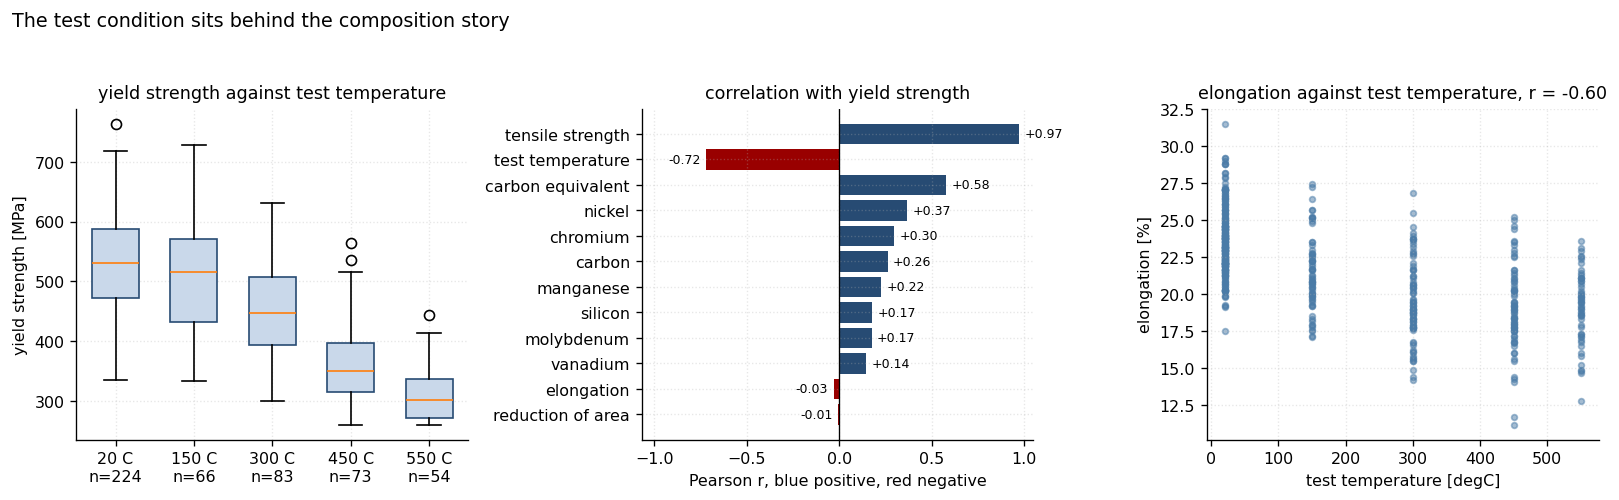

tensile_strength_mpa        0.974
test_temperature_c         -0.718
ce_iiw_carbon_equivalent    0.578
nickel_wt_pct               0.367
chromium_wt_pct             0.297
carbon_wt_pct               0.261
manganese_wt_pct            0.225
silicon_wt_pct              0.175
molybdenum_wt_pct           0.175
vanadium_wt_pct             0.143
elongation_pct             -0.030
reduction_of_area_pct      -0.006

mean yield at 20 C: 532 MPa, above 20 C: 414 MPa
correlation of yield with elongation: -0.030


In [4]:
num = df.select_dtypes("number")
corr_yield = num.corr()["yield_strength_mpa"].drop("yield_strength_mpa").sort_values(key=abs, ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.2))
ax = axes[0]
groups = [df.loc[df.test_temperature_c == t, "yield_strength_mpa"].values
          for t in sorted(df.test_temperature_c.unique())]
labels = [f"{t:.0f} C" + chr(10) + f"n={len(g)}" for t, g in zip(sorted(df.test_temperature_c.unique()), groups)]
bp = ax.boxplot(groups, tick_labels=labels, patch_artist=True, widths=0.6)
for patch in bp["boxes"]:
    patch.set_facecolor("#c9d8ea"); patch.set_edgecolor("#274b73")
ax.set_title("yield strength against test temperature")
ax.set_ylabel("yield strength [MPa]")

ax = axes[1]
pretty = {"test_temperature_c": "test temperature", "ce_iiw_carbon_equivalent": "carbon equivalent",
          "nickel_wt_pct": "nickel", "chromium_wt_pct": "chromium", "carbon_wt_pct": "carbon",
          "manganese_wt_pct": "manganese", "silicon_wt_pct": "silicon",
          "molybdenum_wt_pct": "molybdenum", "vanadium_wt_pct": "vanadium",
          "tensile_strength_mpa": "tensile strength", "elongation_pct": "elongation",
          "reduction_of_area_pct": "reduction of area"}
names = [pretty.get(k, k) for k in corr_yield.index][::-1]
vals = corr_yield.values[::-1]
ax.barh(names, vals, color=["#990000" if c < 0 else "#274b73" for c in vals])
ax.set_title("correlation with yield strength")
ax.set_xlabel("Pearson r, blue positive, red negative")
ax.axvline(0, color="k", lw=0.8)
for name, v in zip(names, vals):
    ax.text(v + (0.03 if v >= 0 else -0.03), name, f"{v:+.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=7.5)
ax.set_xlim(min(vals) - 0.35, 1.05)

ax = axes[2]
ax.scatter(df.test_temperature_c, df.elongation_pct, s=12, alpha=0.5, color="#4a7ba7")
ax.set_title(f"elongation against test temperature, r = {num.corr().loc['test_temperature_c', 'elongation_pct']:.2f}")
ax.set_xlabel("test temperature [degC]"); ax.set_ylabel("elongation [%]")

fig.suptitle("The test condition sits behind the composition story", fontsize=11.5, x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(FIGDIR / "fig1_test_condition.png", dpi=150)
plt.show()

print(corr_yield.round(3).to_string())
print()
print("mean yield at 20 C: %.0f MPa, above 20 C: %.0f MPa"
      % (df.loc[df.test_temperature_c == 20, "yield_strength_mpa"].mean(),
         df.loc[df.test_temperature_c > 20, "yield_strength_mpa"].mean()))
print("correlation of yield with elongation: %.3f" % num.corr().loc["yield_strength_mpa", "elongation_pct"])

## 4 · Strength, weldability and the carbon equivalent limit

The carbon equivalent column is where the strength story meets the fabricator's problem: past
about 0.45 the heat needs preheat before welding. In this file 456 of the 500 heats sit above that
line, which is worth saying out loud, since it means the fleet described here is not a
weldability-friendly population.

weldability_classification
Heavy Preheat Required (CE > 0.45)      456
Fully Weldable (CE <= 0.41)              26
Moderate Preheat (0.41 < CE <= 0.45)     18

carbon equivalent, min 0.268, median 0.663, max 1.161
share above the 0.45 preheat line: 91.2 percent
correlation of carbon equivalent with yield: 0.578


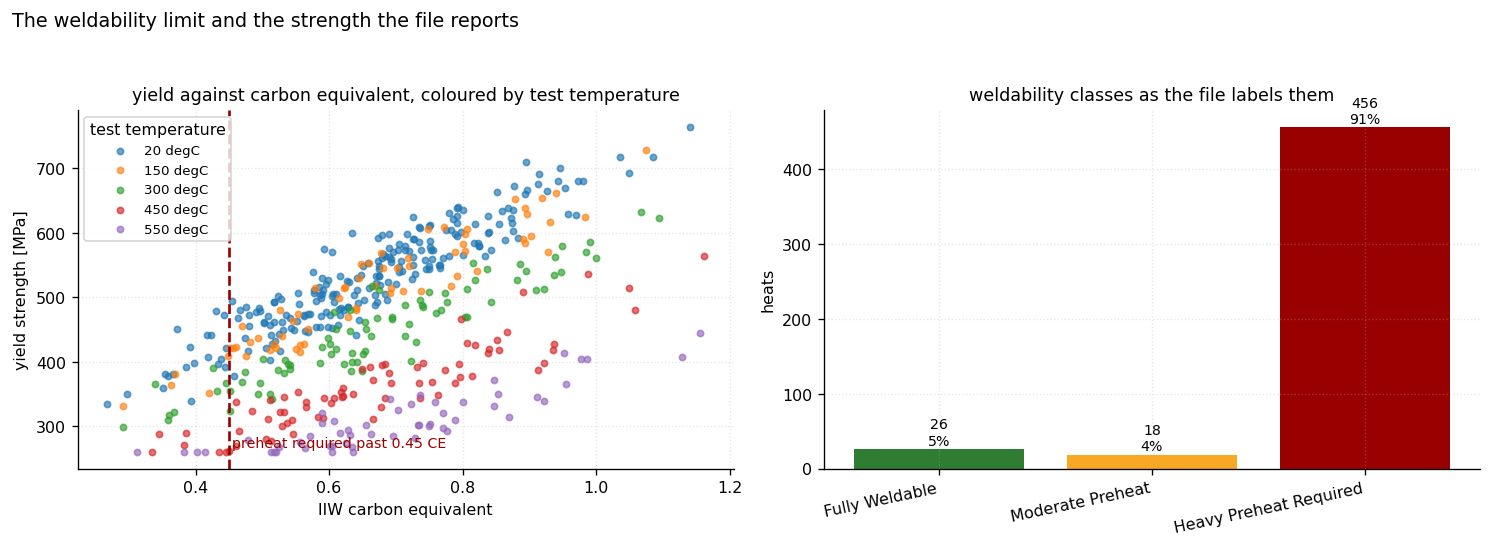

In [5]:
ce = df.ce_iiw_carbon_equivalent
print(df.weldability_classification.value_counts().to_string())
print()
print("carbon equivalent, min %.3f, median %.3f, max %.3f" % (ce.min(), ce.median(), ce.max()))
print("share above the 0.45 preheat line: %.1f percent" % (100 * (ce > 0.45).mean()))
print("correlation of carbon equivalent with yield: %.3f" % ce.corr(df.yield_strength_mpa))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
ax = axes[0]
for (t, sub) in df.groupby("test_temperature_c"):
    ax.scatter(sub.ce_iiw_carbon_equivalent, sub.yield_strength_mpa, s=14, alpha=0.65,
               label=f"{t:.0f} degC")
ax.axvline(0.45, color="#990000", ls="--", lw=1.6)
ax.text(0.455, df.yield_strength_mpa.min() + 8, "preheat required past 0.45 CE",
        color="#990000", fontsize=8.5)
ax.set_xlabel("IIW carbon equivalent"); ax.set_ylabel("yield strength [MPa]")
ax.set_title("yield against carbon equivalent, coloured by test temperature")
ax.legend(title="test temperature", fontsize=8)

ax = axes[1]
order = ["Fully Weldable (CE <= 0.41)", "Moderate Preheat (0.41 < CE <= 0.45)",
         "Heavy Preheat Required (CE > 0.45)"]
counts = df.weldability_classification.value_counts().reindex(order)
ax.bar(range(len(counts)), counts.values, color=["#2e7d32", "#f9a825", "#990000"])
ax.set_xticks(range(len(counts)))
ax.set_xticklabels([o.split(" (")[0] for o in order], rotation=12, ha="right")
for i, v in enumerate(counts.values):
    ax.text(i, v + 6, f"{v}" + chr(10) + f"{100*v/len(df):.0f}%", ha="center", fontsize=8.5)
ax.set_ylabel("heats"); ax.set_title("weldability classes as the file labels them")

fig.suptitle("The weldability limit and the strength the file reports", fontsize=11.5, x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(FIGDIR / "fig2_weldability.png", dpi=150)
plt.show()

## 5 · Derived features, and the equations behind them

Four standard relations turn the chemistry into numbers a metallurgist recognises. I use them as
model inputs later, and I state the assumptions where a relation needs something the file does not
carry.

IIW carbon equivalent, the one the file already contains:

$$CE_{IIW} = C + \frac{Mn}{6} + \frac{Cr + Mo + V}{5} + \frac{Ni + Cu}{15}$$

Ito and Bessyo's cracking parameter, which weights the elements differently and is the one used for
cold cracking rather than for hardenability:

$$P_{cm} = C + \frac{Si}{30} + \frac{Mn + Cu + Cr}{20} + \frac{Ni}{60} + \frac{Mo}{15} + \frac{V}{10} + 5B$$

Andrews' transformation temperatures, which say where the austenite starts to come apart:

$$Ac_1 = 723 - 10.7Mn - 16.9Ni + 29.1Si + 16.9Cr$$
$$Ac_3 = 910 - 203\sqrt{C} - 15.2Ni + 44.7Si + 104V + 31.5Mo$$
$$M_s = 539 - 423C - 30.4Mn - 17.7Ni - 12.1Cr - 7.5Mo$$

Pickering's yield strength for a ferrite-pearlite steel, which is the only one of the four that
needs a grain size:

$$\sigma_y = 15.4\left(3.5 + 2.1Mn + 5.4Si + 23C + \frac{1.13}{\sqrt{d}}\right)$$

The file has no grain size, so I fix d at 10 µm and treat the result as one term with a stated
assumption, not as a prediction. Copper and boron are absent from the file, so those terms drop
out of $P_{cm}$.

In [6]:
f = df.assign(
    pcm=lambda x: (x.carbon_wt_pct + x.silicon_wt_pct / 30
                   + (x.manganese_wt_pct + x.chromium_wt_pct) / 20
                   + x.nickel_wt_pct / 60 + x.molybdenum_wt_pct / 15
                   + x.vanadium_wt_pct / 10),
    ac1=lambda x: (723 - 10.7 * x.manganese_wt_pct - 16.9 * x.nickel_wt_pct
                   + 29.1 * x.silicon_wt_pct + 16.9 * x.chromium_wt_pct),
    ac3=lambda x: (910 - 203 * np.sqrt(x.carbon_wt_pct) - 15.2 * x.nickel_wt_pct
                   + 44.7 * x.silicon_wt_pct + 104 * x.vanadium_wt_pct
                   + 31.5 * x.molybdenum_wt_pct),
    ms=lambda x: (539 - 423 * x.carbon_wt_pct - 30.4 * x.manganese_wt_pct
                  - 17.7 * x.nickel_wt_pct - 12.1 * x.chromium_wt_pct
                  - 7.5 * x.molybdenum_wt_pct),
)
D_GRAIN_MM = 0.010
f["pickering_ys"] = 15.4 * (3.5 + 2.1 * f.manganese_wt_pct + 5.4 * f.silicon_wt_pct
                            + 23 * f.carbon_wt_pct + 1.13 / np.sqrt(D_GRAIN_MM))

derived = f[["pcm", "ac1", "ac3", "ms", "pickering_ys"]].agg(["min", "median", "max"]).round(1)
print(derived.to_string())
print()
print("Pickering term assumed a 10 micron ferrite grain size for every heat")
print(f"its correlation with measured yield at 20 C: "
      f"{f.loc[f.test_temperature_c == 20, 'pickering_ys'].corr(f.loc[f.test_temperature_c == 20, 'yield_strength_mpa']):.3f}")
print(f"its median is {f.pickering_ys.median():.0f} MPa against a measured median of "
      f"{f.yield_strength_mpa.median():.0f} MPa, which is the offset the missing grain size term carries")

        pcm    ac1    ac3     ms  pickering_ys
min     0.2  661.8  752.4  258.4         306.7
median  0.4  723.1  827.4  373.9         390.6
max     0.6  759.8  893.2  471.9         474.1

Pickering term assumed a 10 micron ferrite grain size for every heat
its correlation with measured yield at 20 C: 0.508
its median is 391 MPa against a measured median of 472 MPa, which is the offset the missing grain size term carries


## 6 · Models, and what each one is allowed to see

Three configurations, same ridge regression, same five fold split, so the only thing changing is
the information the model gets:

1. chemistry only, the seven alloying elements;
2. chemistry plus the test temperature;
3. chemistry, test temperature and the four derived features from section 5.

Ridge rather than plain least squares because several of these elements move together, and a
small penalty on the coefficients is the cheap way to keep them from fighting.

                                  R2 cross validated                      RMSE [MPa]               
target                              tensile_strength yield_strength tensile_strength yield_strength
model                                                                                              
chemistry + temperature + derived              0.937          0.936             30.6           27.8
chemistry + test temperature                   0.937          0.936             30.6           27.8
chemistry only                                 0.481          0.387             87.7           86.2

a model that predicts the mean instead scores R2 0.000 with an RMSE of 110.1 MPa


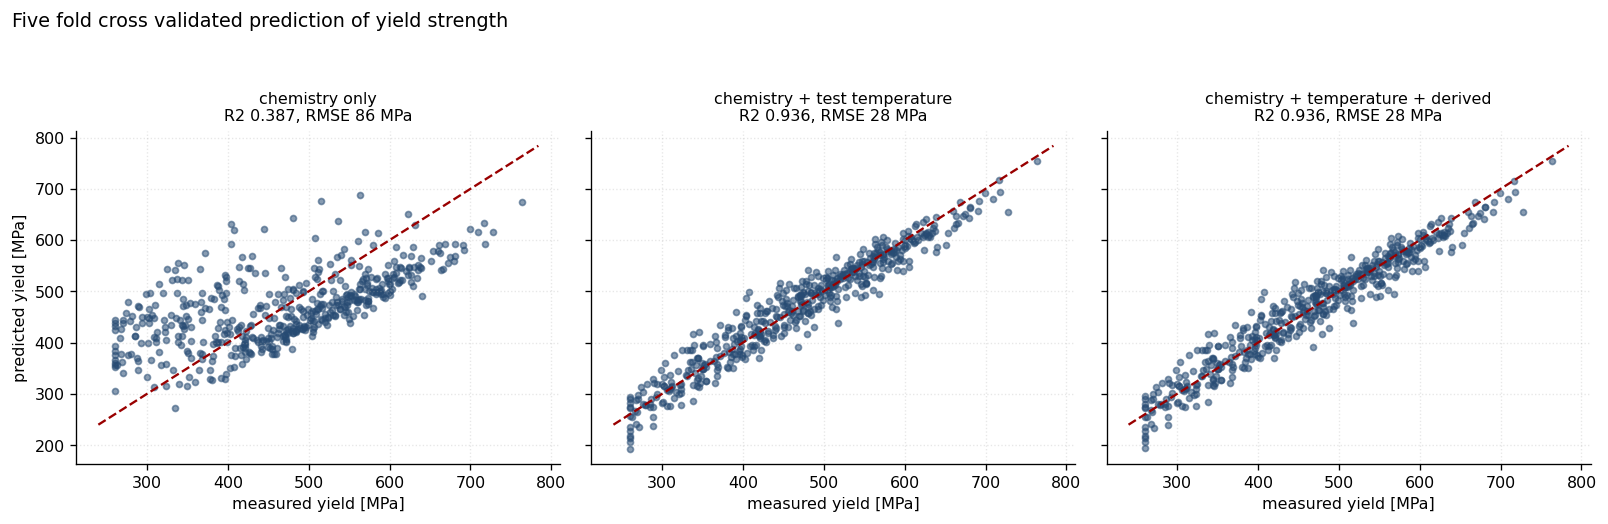

In [7]:
COMP = ["carbon_wt_pct", "silicon_wt_pct", "manganese_wt_pct", "chromium_wt_pct",
        "molybdenum_wt_pct", "nickel_wt_pct", "vanadium_wt_pct"]
DERIVED = ["pcm", "ac1", "ac3", "ms", "pickering_ys"]

def ridge_cv(frame, features, target, folds=5, seed=0):
    X, y = frame[features].to_numpy(float), frame[target].to_numpy(float)
    pipe = Pipeline([("scale", StandardScaler()), ("ridge", Ridge(alpha=1.0))])
    pred = cross_val_predict(pipe, X, y, cv=KFold(folds, shuffle=True, random_state=seed))
    return r2_score(y, pred), float(np.sqrt(mean_squared_error(y, pred))), y, pred

configs = {
    "chemistry only": COMP,
    "chemistry + test temperature": COMP + ["test_temperature_c"],
    "chemistry + temperature + derived": COMP + ["test_temperature_c"] + DERIVED,
}
rows = []
fits = {}
for name, feats in configs.items():
    for target in ("yield_strength_mpa", "tensile_strength_mpa"):
        r2, rmse, y, pred = ridge_cv(f, feats, target)
        rows.append({"model": name, "target": target.replace("_mpa", ""), "features": len(feats),
                     "R2 cross validated": round(r2, 3), "RMSE [MPa]": round(rmse, 1)})
        fits[(name, target)] = (y, pred)

scores = pd.DataFrame(rows)
wide = scores.pivot(index="model", columns="target", values=["R2 cross validated", "RMSE [MPa]"])
print(wide.to_string())
print()
mean_y = f.yield_strength_mpa.mean()
print("a model that predicts the mean instead scores R2 0.000 with an RMSE of %.1f MPa"
      % float(np.sqrt(((f.yield_strength_mpa - mean_y) ** 2).mean())))

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.4), sharey=True)
for ax, (name, feats) in zip(axes, configs.items()):
    y, pred = fits[(name, "yield_strength_mpa")]
    ax.scatter(y, pred, s=13, alpha=0.55, color="#274b73")
    lim = [y.min() - 20, y.max() + 20]
    ax.plot(lim, lim, color="#990000", lw=1.4, ls="--")
    r2, rmse, _, _ = ridge_cv(f, feats, "yield_strength_mpa")
    ax.set_title(f"{name}\nR2 {r2:.3f}, RMSE {rmse:.0f} MPa", fontsize=9.5)
    ax.set_xlabel("measured yield [MPa]")
axes[0].set_ylabel("predicted yield [MPa]")
fig.suptitle("Five fold cross validated prediction of yield strength", fontsize=11.5, x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(FIGDIR / "fig3_model_comparison.png", dpi=150)
plt.show()

## 7 · What the best model leans on

Cross validated R² tells me how much is explained but not by what. Permutation importance answers
the second question by shuffling one column at a time and measuring the damage, which keeps the
scale readable in MPa.

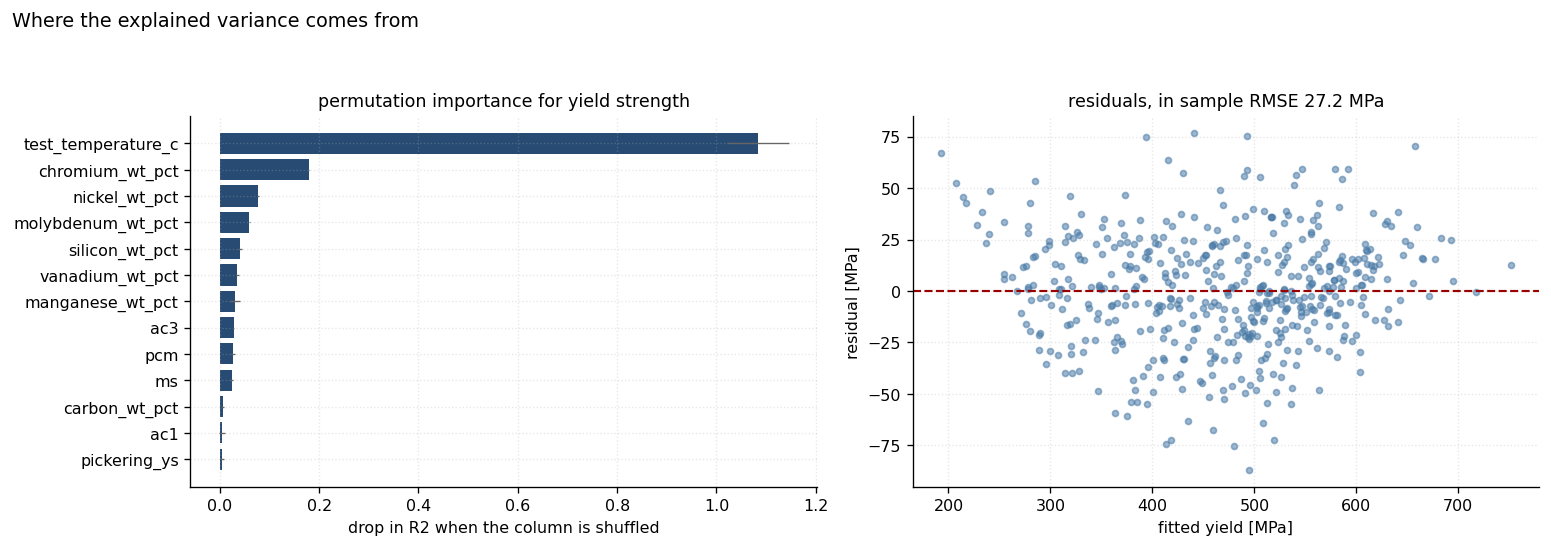

test_temperature_c    1.0835
chromium_wt_pct       0.1792
nickel_wt_pct         0.0773
molybdenum_wt_pct     0.0597
silicon_wt_pct        0.0404
vanadium_wt_pct       0.0349
manganese_wt_pct      0.0303
ac3                   0.0277
pcm                   0.0259
ms                    0.0236
carbon_wt_pct         0.0054
ac1                   0.0042
pickering_ys          0.0039


In [8]:
best_feats = COMP + ["test_temperature_c"] + DERIVED
X, y = f[best_feats].to_numpy(float), f.yield_strength_mpa.to_numpy(float)
pipe = Pipeline([("scale", StandardScaler()), ("ridge", Ridge(alpha=1.0))]).fit(X, y)

result = permutation_importance(pipe, X, y, n_repeats=30, random_state=0, scoring="r2")
imp = pd.Series(result.importances_mean, index=best_feats).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
ax.barh(imp.index, imp.values, xerr=result.importances_std[imp.index.argsort()],
        color="#274b73", error_kw={"ecolor": "0.4", "lw": 0.8})
ax.set_xlabel("drop in R2 when the column is shuffled")
ax.set_title("permutation importance for yield strength")

ax = axes[1]
pred = pipe.predict(X)
ax.scatter(pred, y - pred, s=13, alpha=0.55, color="#4a7ba7")
ax.axhline(0, color="#990000", lw=1.3, ls="--")
ax.set_xlabel("fitted yield [MPa]"); ax.set_ylabel("residual [MPa]")
ax.set_title(f"residuals, in sample RMSE {np.sqrt(mean_squared_error(y, pred)):.1f} MPa")

fig.suptitle("Where the explained variance comes from", fontsize=11.5, x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(FIGDIR / "fig4_importance.png", dpi=150)
plt.show()

print(imp.sort_values(ascending=False).round(4).to_string())

## 8 · Strength, ductility and weldability at one test condition

Pooling the test temperatures muddies any trade-off, so this section fixes the condition: the 224
heats tested at 20 °C, which is the only group large enough to compare like with like. On that
subset I can ask the mill question properly. Given a strength target, what ductility survives, and
what does the carbon equivalent look like while doing it?

heats tested at 20 C: 224
yield median 531 MPa, elongation median 23.3 percent, carbon equivalent median 0.669

             target  heats  median elongation [%]  median CE  share above 0.45 CE [%]
yield >= 355 (S355)    221                   23.3      0.670                     92.3
yield >= 460 (S460)    182                   23.0      0.692                     98.9
yield >= 550 (S550)     94                   22.0      0.786                    100.0

inside these 224 heats, yield against elongation correlates at -0.815
and elongation against carbon equivalent at -0.743


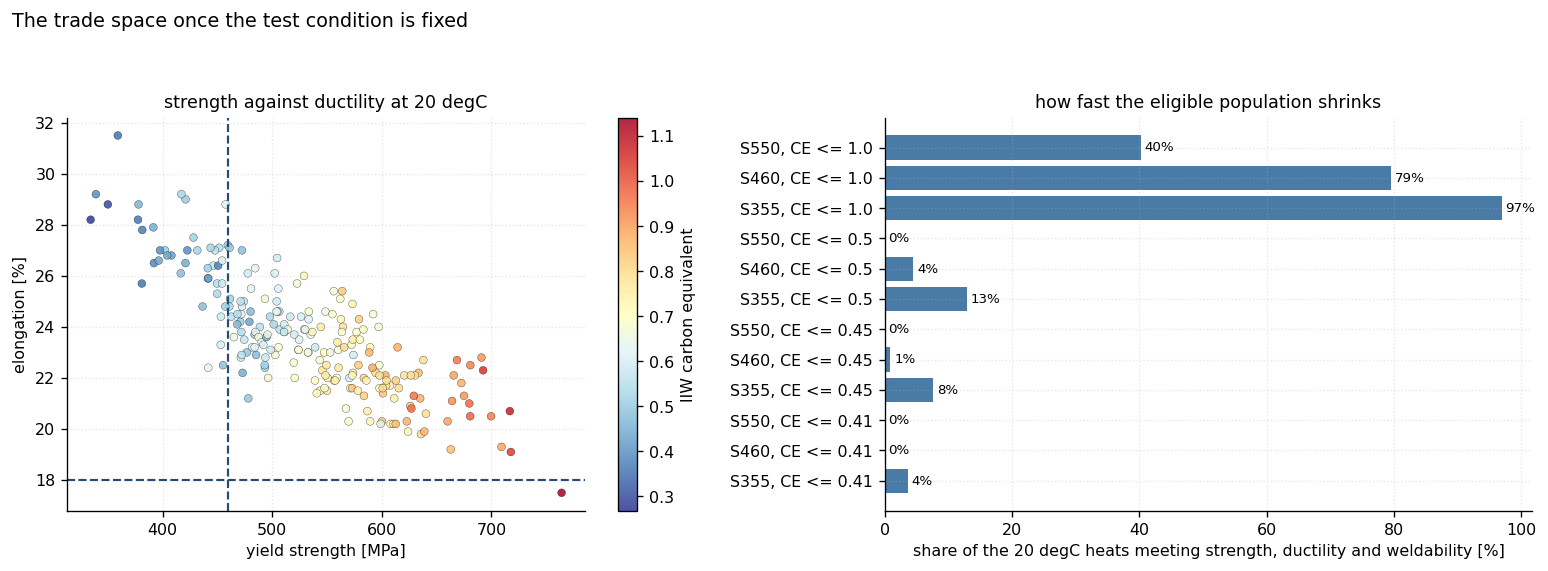

In [9]:
room = f[f.test_temperature_c == 20].copy()
print(f"heats tested at 20 C: {len(room)}")
print("yield median %.0f MPa, elongation median %.1f percent, carbon equivalent median %.3f"
      % (room.yield_strength_mpa.median(), room.elongation_pct.median(), room.ce_iiw_carbon_equivalent.median()))

targets = {"yield >= 355 (S355)": room.yield_strength_mpa >= 355,
           "yield >= 460 (S460)": room.yield_strength_mpa >= 460,
           "yield >= 550 (S550)": room.yield_strength_mpa >= 550}
tbl = []
for label, mask in targets.items():
    sub = room[mask]
    tbl.append({"target": label, "heats": int(mask.sum()),
                "median elongation [%]": round(sub.elongation_pct.median(), 1) if len(sub) else np.nan,
                "median CE": round(sub.ce_iiw_carbon_equivalent.median(), 3) if len(sub) else np.nan,
                "share above 0.45 CE [%]": round(100 * (sub.ce_iiw_carbon_equivalent > 0.45).mean(), 1) if len(sub) else np.nan})
print()
print(pd.DataFrame(tbl).to_string(index=False))
print()
print("inside these 224 heats, yield against elongation correlates at %.3f"
      % room.yield_strength_mpa.corr(room.elongation_pct))
print("and elongation against carbon equivalent at %.3f"
      % room.ce_iiw_carbon_equivalent.corr(room.elongation_pct))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
sc = ax.scatter(room.yield_strength_mpa, room.elongation_pct, c=room.ce_iiw_carbon_equivalent,
                cmap="RdYlBu_r", s=22, alpha=0.85, edgecolor="k", linewidth=0.2)
cb = fig.colorbar(sc, ax=ax); cb.set_label("IIW carbon equivalent")
ax.axvline(460, color="#274b73", ls="--", lw=1.3); ax.axhline(18, color="#274b73", ls="--", lw=1.3)
ax.set_xlabel("yield strength [MPa]"); ax.set_ylabel("elongation [%]")
ax.set_title("strength against ductility at 20 degC")

ax = axes[1]
share = []
labels = []
for ce_max in (0.41, 0.45, 0.50, 1.00):
    for ymin, name in ((355, "S355"), (460, "S460"), (550, "S550")):
        ok = (room.yield_strength_mpa >= ymin) & (room.ce_iiw_carbon_equivalent <= ce_max) & (room.elongation_pct >= 18)
        share.append(100 * ok.mean()); labels.append(f"{name}, CE <= {ce_max if ce_max < 1 else 1.0}")
ax.barh(labels, share, color="#4a7ba7")
ax.set_xlabel("share of the 20 degC heats meeting strength, ductility and weldability [%]")
ax.set_title("how fast the eligible population shrinks")
for i, v in enumerate(share):
    ax.text(v + 0.6, i, f"{v:.0f}%", va="center", fontsize=8)

fig.suptitle("The trade space once the test condition is fixed", fontsize=11.5, x=0.01, ha="left")
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(FIGDIR / "fig5_trade_space.png", dpi=150)
plt.show()

## 9 · The composition-only model, on one test condition

One more comparison, because it is the honest version of the question I started with. Fit on the
20 °C heats only and the chemistry has to explain the spread without help from the test
temperature. If the R² drops from the pooled value, part of the earlier fit was the test condition
talking.

         subset                     features           target    R2  RMSE [MPa]
  all 500 heats               chemistry only   yield_strength 0.387        86.2
  all 500 heats               chemistry only tensile_strength 0.481        87.7
  all 500 heats with temperature and derived tensile_strength 0.937        30.6
20 C heats only               chemistry only   yield_strength 0.948        18.3
20 C heats only               chemistry only tensile_strength 0.951        21.5
20 C heats only with temperature and derived tensile_strength 0.951        21.5

within the 20 C heats, chemistry alone reaches R2 0.948 and RMSE 18.3 MPa
the spread of yield in that subset is 80.7 MPa, so the model leaves 23 percent of one standard deviation unexplained


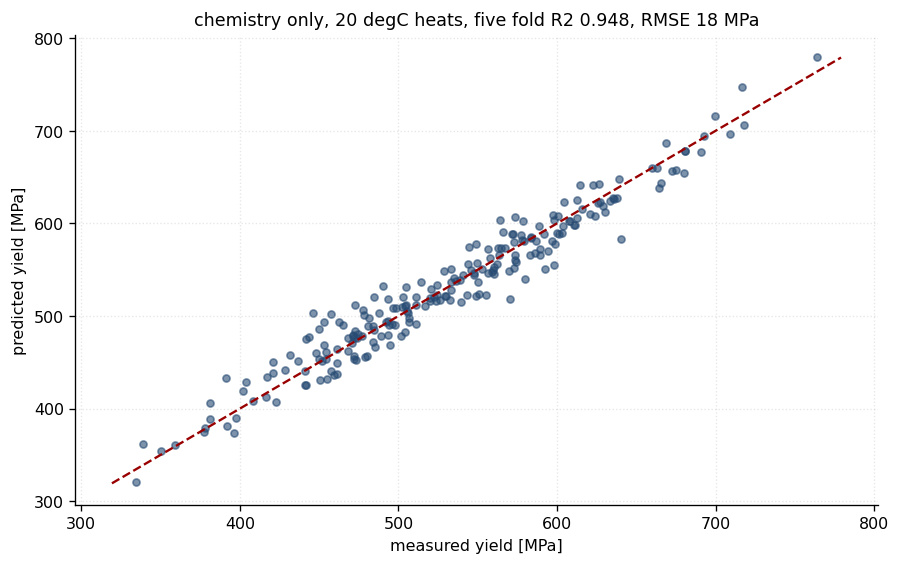

In [10]:
rows = []
for label, frame in (("all 500 heats", f), ("20 C heats only", room)):
    for target in ("yield_strength_mpa", "tensile_strength_mpa"):
        r2, rmse, _, _ = ridge_cv(frame, COMP, target)
        rows.append({"subset": label, "features": "chemistry only", "target": target.replace("_mpa", ""),
                     "R2": round(r2, 3), "RMSE [MPa]": round(rmse, 1)})
    r2, rmse, _, _ = ridge_cv(frame, COMP + ["test_temperature_c"] + DERIVED, target)
    rows.append({"subset": label, "features": "with temperature and derived", "target": target.replace("_mpa", ""),
                 "R2": round(r2, 3), "RMSE [MPa]": round(rmse, 1)})
subset_scores = pd.DataFrame(rows)
print(subset_scores.to_string(index=False))
print()
r2_room, rmse_room, y_room, pred_room = ridge_cv(room, COMP, "yield_strength_mpa")
print(f"within the 20 C heats, chemistry alone reaches R2 {r2_room:.3f} and RMSE {rmse_room:.1f} MPa")
print(f"the spread of yield in that subset is {room.yield_strength_mpa.std():.1f} MPa, so the model leaves "
      f"{100 * rmse_room / room.yield_strength_mpa.std():.0f} percent of one standard deviation unexplained")

fig, ax = plt.subplots(figsize=(7.6, 4.8))
ax.scatter(y_room, pred_room, s=18, alpha=0.6, color="#274b73")
lim = [y_room.min() - 15, y_room.max() + 15]
ax.plot(lim, lim, color="#990000", lw=1.4, ls="--")
ax.set_xlabel("measured yield [MPa]"); ax.set_ylabel("predicted yield [MPa]")
ax.set_title(f"chemistry only, 20 degC heats, five fold R2 {r2_room:.3f}, RMSE {rmse_room:.0f} MPa")
fig.tight_layout()
fig.savefig(FIGDIR / "fig6_room_temperature_only.png", dpi=150)
plt.show()

## 10 · What I take from this, and what the file cannot say

The numbers above, in the order they matter to me:

- The test condition dominates the pooled file. Test temperature correlates with yield strength at
  about -0.72, against 0.58 for the carbon equivalent and 0.14 to 0.37 for the individual elements,
  and it is worth more in the fitted model than every other column combined. Mean yield is 532 MPa
  at 20 °C and 414 MPa above it.
- Pooled, chemistry alone reaches R² 0.387 for yield and 0.481 for tensile strength, with RMSE
  around 86 and 88 MPa. Adding the test temperature takes both to 0.937. The four derived features
  change nothing visible: 0.936 against 0.936 for yield, which is what I expected once the
  temperature term was in.
- Inside the 224 heats tested at 20 °C, where the condition is constant, chemistry alone reaches
  R² 0.948 for yield with an RMSE of 18.3 MPa against a yield spread of 80.7 MPa. Chemistry
  explains this steel well once the confound is removed, and the pooled number was understating it
  rather than the reverse.
- Chromium and nickel carry the most weight of the elements in the fitted model, ahead of carbon.
  I would not push that far: the elements move together in this file, so the credit between them is
  partly arbitrary, and the carbon equivalent column, which is a combination of them, correlates
  more strongly than any single element.
- Ductility does trade against strength, and pooling hides it. Across the file the correlation
  between yield and elongation is -0.03, so a pooled analysis would report no compromise at all.
  Inside the 224 heats tested at 20 °C it is -0.815, and elongation against the carbon equivalent is
  -0.743. The trade-off is in this file; the test temperature was drowning it.
- This population is strength rich and welding poor. Of the 224 heats at 20 °C, 221 clear S355 and
  182 clear S460, but 92 percent of the S355 group and 99 percent of the S460 group sit above the
  0.45 carbon equivalent preheat line. Nothing in the file reaches S355 with weldability and
  ductility intact at any meaningful rate.

Three limits, stated because the file cannot settle them:

1. No processing variables. Grain size, cooling rate, finishing temperature and reduction ratio are
   all absent, and they are what a mill actually manipulates. The Pickering term in section 5
   carries an assumed 10 µm grain size for that reason, and its median of 391 MPa sits about 80 MPa
   below the measured median, which is the size of the offset that assumption carries.
2. Two of the fifteen columns are derived. The carbon equivalent and the weldability label follow
   from the chemistry, so they add no information a model does not already have, and a model that
   leans on them is leaning on arithmetic.
3. No provenance I can verify. The file has 500 rows, sequential ids and no origin I can confirm,
   and the description shipped with it names a different dataset. Treat the numbers as a well
   formed exercise on tensile data, not as a record of a particular mill or heat.

In [11]:
figs = sorted(FIGDIR.glob("*.png"))
print("figures written by this notebook")
for p in figs:
    print(f"  {p.name:38} {p.stat().st_size / 1024:.0f} kB")
print()
print(f"cells: {len(df)} heats, {f.shape[1]} columns after feature engineering")

figures written by this notebook
  fig1_test_condition.png                139 kB
  fig2_weldability.png                   167 kB
  fig3_model_comparison.png              201 kB
  fig4_importance.png                    137 kB
  fig5_trade_space.png                   168 kB
  fig6_room_temperature_only.png         82 kB

cells: 500 heats, 20 columns after feature engineering
